# EDA ETTm1 & ETTm2

**Ghi chú kết quả** được đặt ngay sau từng phần phân tích.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE_URL = "https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/"

df_m1 = pd.read_csv(BASE_URL + "ETTm1.csv")
df_m2 = pd.read_csv(BASE_URL + "ETTm2.csv")

print("ETTm1 shape:", df_m1.shape)
print("ETTm2 shape:", df_m2.shape)

print("\nETTm1 - First 5 rows:")
display(df_m1.head())

print("\nETTm2 - First 5 rows:")
display(df_m2.head())

ETTm1 shape: (69680, 8)
ETTm2 shape: (69680, 8)

ETTm1 - First 5 rows:


,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
0,2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000
1,2016-07-01 00:15:00,5.760,2.076,1.492,0.426,4.264,1.401,30.459999
2,2016-07-01 00:30:00,5.760,1.942,1.492,0.391,4.234,1.310,30.038000
3,2016-07-01 00:45:00,5.760,1.942,1.492,0.426,4.234,1.310,27.013000
4,2016-07-01 01:00:00,5.693,2.076,1.492,0.426,4.142,1.371,27.787001



ETTm2 - First 5 rows:


,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
0,2016-07-01 00:00:00,41.130001,12.481,36.535999,9.355,4.424,1.311,38.661999
1,2016-07-01 00:15:00,39.622002,11.309,35.543999,8.551,3.209,1.258,38.223000
2,2016-07-01 00:30:00,38.868000,10.555,34.365002,7.586,4.435,1.258,37.344002
3,2016-07-01 00:45:00,35.518002,9.214,32.569000,8.712,4.435,1.215,37.124001
4,2016-07-01 01:00:00,37.528000,10.136,33.936001,7.532,4.435,1.215,37.124001


In [ ]:
for name, df in [("ETTm1", df_m1), ("ETTm2", df_m2)]:
    print(f"\n{'='*15} {name} {'='*15}")

    print("\nColumns and data types:")
    print(df.dtypes)

    print("\nTime range:")
    dates = pd.to_datetime(df["date"])

    print("Start:", dates.min())
    print("End:  ", dates.max())

    print("\nNumber of rows:", len(df))


=============== ETTm1 ===============

Columns and data types:
date     object
HUFL    float64
HULL    float64
MUFL    float64
MULL    float64
LUFL    float64
LULL    float64
OT      float64
dtype: object

Time range:
Start: 2016-07-01 00:00:00
End:   2018-06-26 19:45:00

Number of rows: 69680

=============== ETTm2 ===============

Columns and data types:
date     object
HUFL    float64
HULL    float64
MUFL    float64
MULL    float64
LUFL    float64
LULL    float64
OT      float64
dtype: object

Time range:
Start: 2016-07-01 00:00:00
End:   2018-06-26 19:45:00

Number of rows: 69680


> **Nhận xét – dữ liệu đầu vào:** ETTm1 và ETTm2 đều có 69.680 dòng, 8 cột; thời gian quan sát từ 01/07/2016 đến 26/06/2018. Cột `date` cần chuyển sang kiểu datetime để phân tích chuỗi thời gian.

In [ ]:
# Convert date to datetime
df_m1["date"] = pd.to_datetime(df_m1["date"], errors="coerce")
df_m2["date"] = pd.to_datetime(df_m2["date"], errors="coerce")

for name, df in [("ETTm1", df_m1), ("ETTm2", df_m2)]:
    print(f"\n{'='*15} {name} {'='*15}")

    # 1. Missing or invalid timestamps
    print("Missing/invalid timestamps:", df["date"].isna().sum())

    # 2. Duplicate timestamps
    print("Duplicate timestamps:", df["date"].duplicated().sum())

    # 3. Expected timestamps at 15-minute intervals
    actual_dates = pd.DatetimeIndex(df["date"].dropna())

    expected_dates = pd.date_range(
        start=actual_dates.min(),
        end=actual_dates.max(),
        freq="15min"
    )

    missing_dates = expected_dates.difference(actual_dates)

    print("Expected timestamps:", len(expected_dates))
    print("Actual unique timestamps:", actual_dates.nunique())
    print("Missing 15-minute timestamps:", len(missing_dates))

    # 4. Check timestamp gaps in chronological order
    time_diff = df["date"].dropna().sort_values().diff()

    print("\nTimestamp interval distribution:")
    print(time_diff.value_counts().head(10))

    if len(missing_dates) > 0:
        print("\nFirst missing timestamps:")
        print(missing_dates[:10])


=============== ETTm1 ===============
Missing/invalid timestamps: 0
Duplicate timestamps: 0
Expected timestamps: 69680
Actual unique timestamps: 69680
Missing 15-minute timestamps: 0

Timestamp interval distribution:
date
0 days 00:15:00    69679
Name: count, dtype: int64

=============== ETTm2 ===============
Missing/invalid timestamps: 0
Duplicate timestamps: 0
Expected timestamps: 69680
Actual unique timestamps: 69680
Missing 15-minute timestamps: 0

Timestamp interval distribution:
date
0 days 00:15:00    69679
Name: count, dtype: int64


> **Nhận xét – timestamp:** Không có timestamp thiếu, không có timestamp trùng. Toàn bộ 69.679 khoảng cách giữa các bản ghi liên tiếp là 15 phút trong cả hai bộ dữ liệu.

In [ ]:
sensor_cols = [
    "HUFL", "HULL", "MUFL",
    "MULL", "LUFL", "LULL", "OT"
]

for name, df in [("ETTm1", df_m1), ("ETTm2", df_m2)]:
    print(f"\n{'='*15} {name} {'='*15}")

    missing_count = df[sensor_cols].isna().sum()
    missing_pct = (missing_count / len(df) * 100).round(4)

    missing_report = pd.DataFrame({
        "Missing Count": missing_count,
        "Missing (%)": missing_pct
    })

    display(missing_report)

    print(
        "Rows with at least one missing sensor value:",
        df[sensor_cols].isna().any(axis=1).sum()
    )


=============== ETTm1 ===============


,Missing Count,Missing (%)
HUFL,0,0.0
HULL,0,0.0
MUFL,0,0.0
MULL,0,0.0
LUFL,0,0.0
LULL,0,0.0
OT,0,0.0


Rows with at least one missing sensor value: 0

=============== ETTm2 ===============


,Missing Count,Missing (%)
HUFL,0,0.0
HULL,0,0.0
MUFL,0,0.0
MULL,0,0.0
LUFL,0,0.0
LULL,0,0.0
OT,0,0.0


Rows with at least one missing sensor value: 0


> **Nhận xét – missing values:** Cả 7 biến đo lường đều không có giá trị thiếu. Không cần nội suy dữ liệu gốc.

In [ ]:
for name, df in [("ETTm1", df_m1), ("ETTm2", df_m2)]:
    print(f"\n{'='*15} {name} {'='*15}")

    report = pd.DataFrame({
        "Min": df[sensor_cols].min(),
        "Max": df[sensor_cols].max(),
        "Mean": df[sensor_cols].mean(),
        "Negative Count": (df[sensor_cols] < 0).sum(),
        "Negative (%)": (
            (df[sensor_cols] < 0).sum() / len(df) * 100
        ).round(2),
        "Zero Count": (df[sensor_cols] == 0).sum(),
        "Infinite Count": pd.Series(
            np.isinf(df[sensor_cols]).sum(),
            index=sensor_cols
        )
    })

    display(report.round(3))


=============== ETTm1 ===============


,Min,Max,Mean,Negative Count,Negative (%),Zero Count,Infinite Count
HUFL,-23.242,24.180,7.414,9240,13.26,344,0
HULL,-5.693,10.315,2.261,9313,13.37,1648,0
MUFL,-26.367,18.087,4.322,11726,16.83,386,0
MULL,-6.041,7.853,0.897,19818,28.44,1006,0
LUFL,-1.188,8.498,3.083,2,0.00,240,0
LULL,-1.371,3.046,0.858,6671,9.57,842,0
OT,-4.221,46.007,13.321,623,0.89,432,0



=============== ETTm2 ===============


,Min,Max,Mean,Negative Count,Negative (%),Zero Count,Infinite Count
HUFL,0.000,107.893,37.219,0,0.00,228,0
HULL,-29.319,36.439,8.554,778,1.12,15389,0
MUFL,10.427,93.230,43.861,0,0.00,0,0
MULL,-6.648,29.808,8.340,1201,1.72,4227,0
LUFL,-14.617,17.218,-3.431,38878,55.80,4725,0
LULL,-31.462,3.731,-2.085,35980,51.64,22829,0
OT,-2.647,58.877,26.610,68,0.10,1,0


> **Nhận xét – khoảng giá trị:** Nhiều biến tải chứa giá trị âm; nổi bật là LUFL (55,80%) và LULL (51,64%) của ETTm2. OT cũng có một tỷ lệ nhỏ giá trị âm. Chưa có căn cứ coi mọi giá trị âm là lỗi; giữ nguyên dữ liệu để phân tích.

In [ ]:
for name, df in [("ETTm1", df_m1), ("ETTm2", df_m2)]:

    print(f"\n{'='*15} {name} {'='*15}")

    # Tạo chỉ số tổng hợp thử nghiệm, chưa coi là công suất thực
    df["load_index"] = df["HUFL"] + df["MUFL"] + df["LUFL"]

    print("Minimum:", round(df["load_index"].min(), 3))
    print("Maximum:", round(df["load_index"].max(), 3))
    print("Mean:", round(df["load_index"].mean(), 3))

    negative_count = (df["load_index"] < 0).sum()

    print("Negative count:", negative_count)
    print("Negative (%):", round(negative_count / len(df) * 100, 2))

    print("\nPercentiles:")
    print(
        df["load_index"]
        .quantile([0.01, 0.05, 0.50, 0.95, 0.99])
        .round(3)
    )


=============== ETTm1 ===============
Minimum: -47.111
Maximum: 48.121
Mean: 14.819
Negative count: 9252
Negative (%): 13.28

Percentiles:
0.01   -30.884
0.05   -17.925
0.50    17.591
0.95    31.603
0.99    38.151
Name: load_index, dtype: float64

=============== ETTm2 ===============
Minimum: 10.615
Maximum: 212.93
Mean: 77.65
Negative count: 0
Negative (%): 0.0

Percentiles:
0.01     30.302
0.05     45.949
0.50     77.408
0.95    110.712
0.99    132.189
Name: load_index, dtype: float64


> **Nhận xét – chỉ số tải thử nghiệm:** `load_index = HUFL + MUFL + LUFL` có 13,28% giá trị âm ở ETTm1, nhưng không âm ở ETTm2. P95/P99 toàn kỳ lần lượt là 31,603/38,151 (ETTm1) và 110,712/132,189 (ETTm2). Chỉ số này **chưa được xác minh là công suất vật lý**, không dùng trực tiếp làm tỷ lệ công suất thực.

In [ ]:
# Kiểm tra tỷ lệ load_index âm theo tháng

for name, df in [("ETTm1", df_m1), ("ETTm2", df_m2)]:
    print(f"\n{'='*15} {name} {'='*15}")

    monthly_negative = (
        df.assign(
            month=df["date"].dt.to_period("M"),
            is_negative=df["load_index"] < 0
        )
        .groupby("month")["is_negative"]
        .agg(["sum", "mean"])
    )

    monthly_negative.columns = [
        "Negative Count",
        "Negative Rate"
    ]

    monthly_negative["Negative Rate"] *= 100

    # Chỉ hiển thị các tháng có giá trị âm
    monthly_negative = monthly_negative[
        monthly_negative["Negative Count"] > 0
    ]

    print("Months with negative load_index:")
    display(monthly_negative.round(2))

    # Đếm chuỗi giá trị âm liên tiếp
    is_negative = df.sort_values("date")["load_index"] < 0

    groups = is_negative.ne(is_negative.shift()).cumsum()

    negative_runs = (
        is_negative.groupby(groups)
        .agg(["first", "size"])
    )

    negative_runs = negative_runs[
        negative_runs["first"]
    ]

    if not negative_runs.empty:
        print(
            "Longest consecutive negative run:",
            negative_runs["size"].max(),
            "records"
        )
        print(
            "Duration (hours):",
            negative_runs["size"].max() * 0.25
        )
    else:
        print("No negative runs")


=============== ETTm1 ===============
Months with negative load_index:


,Negative Count,Negative Rate
month,,
2017-01,172,5.78
2017-02,407,15.14
2017-03,437,14.68
2017-04,698,24.24
2017-05,778,26.14
2017-06,550,19.10
2017-07,586,19.69
2017-08,529,17.78
2017-09,466,16.18


Longest consecutive negative run: 43 records
Duration (hours): 10.75

=============== ETTm2 ===============
Months with negative load_index:


,Negative Count,Negative Rate
month,,


No negative runs


> **Nhận xét – giá trị âm theo thời gian:** ETTm1 bắt đầu có `load_index` âm từ tháng 01/2017 và xuất hiện trong 18 tháng liên tiếp đến 06/2018; chuỗi âm dài nhất 43 bản ghi (10,75 giờ). Đây là hiện tượng có cấu trúc theo thời gian, không chỉ vài ngoại lai đơn lẻ.

In [ ]:
# Tìm bản ghi đầu tiên có load_index âm trong ETTm1
negative_rows = df_m1[df_m1["load_index"] < 0]

first_negative_date = negative_rows["date"].min()

print("First negative load_index:", first_negative_date)

# Xem các bản ghi trong khoảng +/- 2 giờ
window = df_m1[
    (df_m1["date"] >= first_negative_date - pd.Timedelta(hours=2))
    & (df_m1["date"] <= first_negative_date + pd.Timedelta(hours=2))
]

display(
    window[
        ["date", "HUFL", "MUFL", "LUFL", "load_index", "OT"]
    ].round(3)
)

First negative load_index: 2017-01-15 12:00:00


,date,HUFL,MUFL,LUFL,load_index,OT
19048,2017-01-15 10:00:00,3.751,0.355,3.137,7.243,4.713
19049,2017-01-15 10:15:00,2.947,-0.320,3.168,5.795,4.362
19050,2017-01-15 10:30:00,2.746,-0.462,3.503,5.787,4.713
19051,2017-01-15 10:45:00,3.751,-0.391,3.533,6.893,5.698
19052,2017-01-15 11:00:00,3.215,-0.782,3.716,6.149,5.979
19053,2017-01-15 11:15:00,2.612,-1.564,3.686,4.734,5.909
19054,2017-01-15 11:30:00,1.407,-1.777,3.229,2.859,5.909
19055,2017-01-15 11:45:00,0.335,-2.097,3.076,1.314,6.120
19056,2017-01-15 12:00:00,-0.268,-3.553,2.924,-0.897,5.909
19057,2017-01-15 12:15:00,0.603,-2.594,2.680,0.689,6.050


> **Nhận xét – trường hợp đầu tiên:** Giá trị `load_index` âm đầu tiên xảy ra lúc 12:00 ngày 15/01/2017 (−0,897), khi HUFL và MUFL cùng âm. Một trường hợp đơn lẻ chưa đủ để xác định nguyên nhân hoặc cơ chế đo.

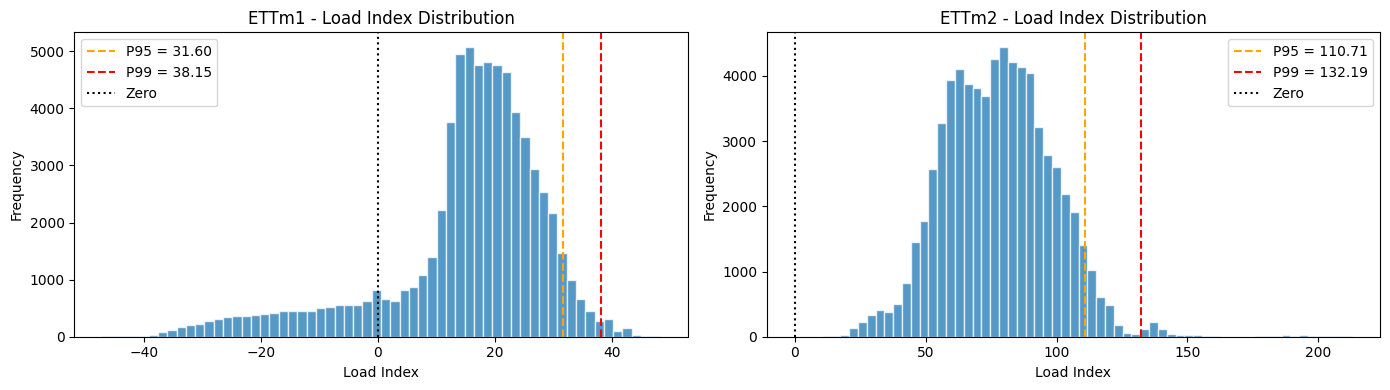

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, (name, df) in zip(
    axes, [("ETTm1", df_m1), ("ETTm2", df_m2)]
):
    values = df["load_index"]

    ax.hist(values, bins=60, alpha=0.75, edgecolor="white")

    ax.axvline(
        values.quantile(0.95),
        color="orange",
        linestyle="--",
        label=f"P95 = {values.quantile(0.95):.2f}"
    )

    ax.axvline(
        values.quantile(0.99),
        color="red",
        linestyle="--",
        label=f"P99 = {values.quantile(0.99):.2f}"
    )

    ax.axvline(
        0,
        color="black",
        linestyle=":",
        label="Zero"
    )

    ax.set_title(f"{name} - Load Index Distribution")
    ax.set_xlabel("Load Index")
    ax.set_ylabel("Frequency")
    ax.legend()

plt.tight_layout()
plt.show()

> **Nhận xét – histogram:** ETTm1 có đuôi trái dài với vùng chỉ số âm đáng kể; ETTm2 tập trung ở miền dương và có đuôi phải kéo dài. P95/P99 trên hình dùng để **mô tả toàn kỳ**, chưa phải tham số vận hành.

In [ ]:
# Split theo thời gian, không shuffle

start_date = pd.Timestamp("2016-07-01")
split_date = start_date + pd.DateOffset(months=16)

print("Calibration start:", start_date)
print("Split date:", split_date)

datasets = {
    "ETTm1": df_m1,
    "ETTm2": df_m2
}

for name, df in datasets.items():

    calibration = df[df["date"] < split_date].copy()
    operation = df[df["date"] >= split_date].copy()

    print(f"\n{'='*15} {name} {'='*15}")

    print("Calibration rows:", len(calibration))
    print("Calibration range:",
          calibration["date"].min(),
          "to",
          calibration["date"].max())

    print("Operation rows:", len(operation))
    print("Operation range:",
          operation["date"].min(),
          "to",
          operation["date"].max())

    print("\nLoad Index Statistics:")

    comparison = pd.DataFrame({
        "Calibration": calibration["load_index"].quantile(
            [0.50, 0.95, 0.99]
        ),
        "Operation": operation["load_index"].quantile(
            [0.50, 0.95, 0.99]
        )
    })

    display(comparison.round(3))

Calibration start: 2016-07-01 00:00:00
Split date: 2017-11-01 00:00:00

=============== ETTm1 ===============
Calibration rows: 46848
Calibration range: 2016-07-01 00:00:00 to 2017-10-31 23:45:00
Operation rows: 22832
Operation range: 2017-11-01 00:00:00 to 2018-06-26 19:45:00

Load Index Statistics:


,Calibration,Operation
0.50,16.969,19.147
0.95,31.211,31.971
0.99,39.359,35.438



=============== ETTm2 ===============
Calibration rows: 46848
Calibration range: 2016-07-01 00:00:00 to 2017-10-31 23:45:00
Operation rows: 22832
Operation range: 2017-11-01 00:00:00 to 2018-06-26 19:45:00

Load Index Statistics:


,Calibration,Operation
0.50,84.098,62.108
0.95,114.044,94.904
0.99,137.392,108.069


> **Nhận xét – chia tập:** Hiệu chuẩn: 01/07/2016–31/10/2017 (46.848 dòng); vận hành: 01/11/2017–26/06/2018 (22.832 dòng). P99 hiệu chuẩn là 39,359 (ETTm1), 137,392 (ETTm2). Không dùng thống kê của giai đoạn vận hành để chọn ngưỡng.

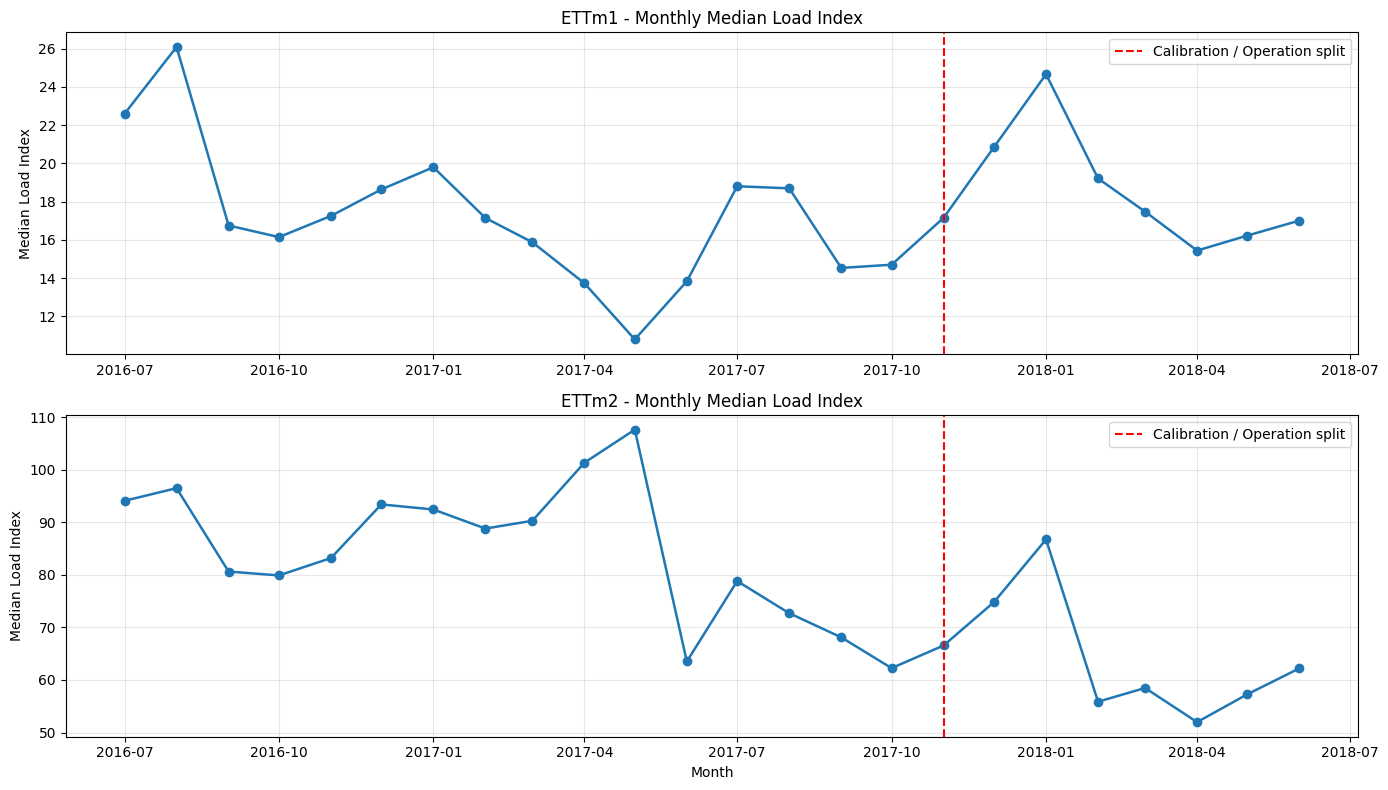

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

for ax, (name, df) in zip(
    axes,
    [("ETTm1", df_m1), ("ETTm2", df_m2)]
):
    monthly = (
        df.set_index("date")["load_index"]
        .resample("MS")
        .median()
    )

    ax.plot(
        monthly.index,
        monthly.values,
        marker="o",
        linewidth=1.8
    )

    ax.axvline(
        pd.Timestamp("2017-11-01"),
        color="red",
        linestyle="--",
        label="Calibration / Operation split"
    )

    ax.set_title(f"{name} - Monthly Median Load Index")
    ax.set_ylabel("Median Load Index")
    ax.grid(alpha=0.3)
    ax.legend()

plt.xlabel("Month")
plt.tight_layout()
plt.show()


> **Nhận xét – trung vị theo tháng:** ETTm1 dao động nhưng chưa thấy xu hướng dài hạn rõ ràng. ETTm2 có mức tải điển hình giảm đáng kể sau giữa năm 2017; điều này góp phần giải thích sự khác biệt giữa hai giai đoạn. Chưa thể tách riêng ảnh hưởng mùa vụ và thay đổi chế độ vận hành.

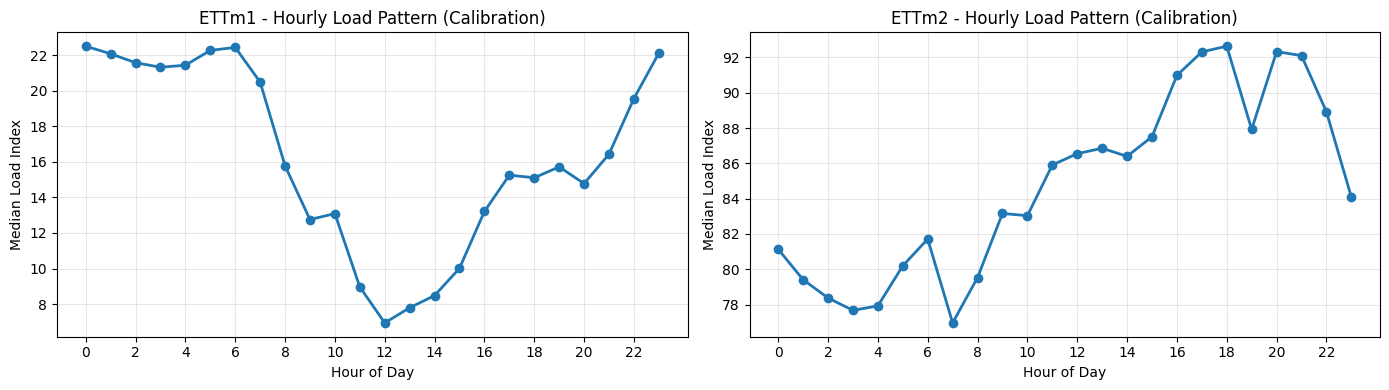

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, (name, df) in zip(
    axes,
    [("ETTm1", df_m1), ("ETTm2", df_m2)]
):
    # Chỉ sử dụng dữ liệu calibration để quan sát
    calibration = df[
        df["date"] < pd.Timestamp("2017-11-01")
    ].copy()

    calibration["hour"] = calibration["date"].dt.hour

    hourly_pattern = (
        calibration
        .groupby("hour")["load_index"]
        .median()
    )

    ax.plot(
        hourly_pattern.index,
        hourly_pattern.values,
        marker="o",
        linewidth=2
    )

    ax.set_title(f"{name} - Hourly Load Pattern (Calibration)")
    ax.set_xlabel("Hour of Day")
    ax.set_ylabel("Median Load Index")
    ax.set_xticks(range(0, 24, 2))
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

> **Nhận xét – chu kỳ ngày:** ETTm1 có trung vị tải cao ban đêm và thấp quanh trưa; ETTm2 cao hơn vào chiều/tối. Hai trạm cần hồ sơ tham chiếu theo giờ riêng; các đường là trung vị trong tập hiệu chuẩn, không phải công suất định mức.

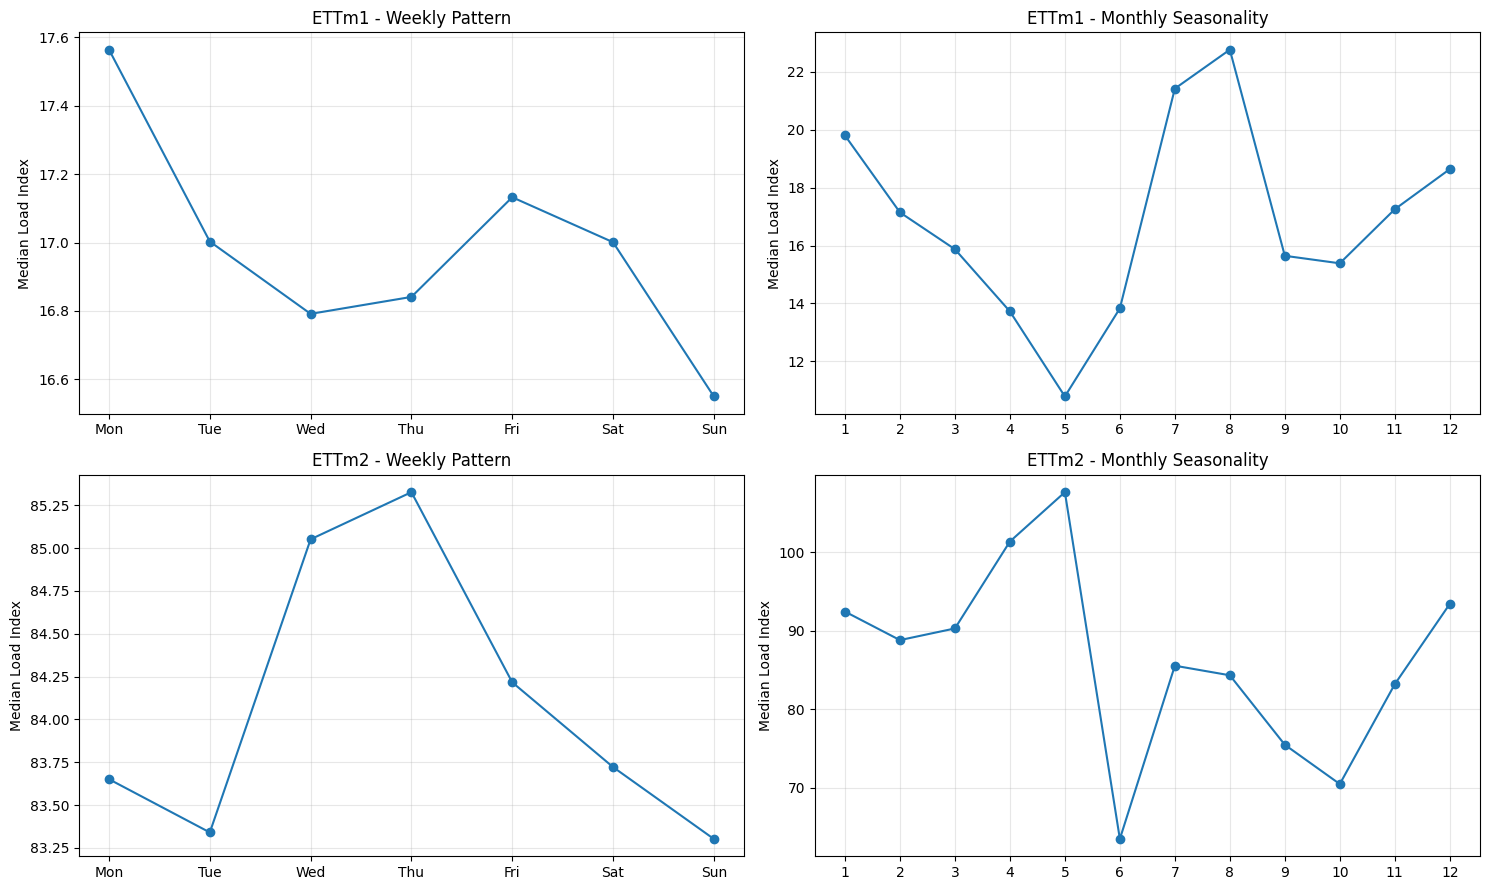

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

calibration_data = {
    "ETTm1": df_m1[df_m1["date"] < "2017-11-01"].copy(),
    "ETTm2": df_m2[df_m2["date"] < "2017-11-01"].copy()
}

fig, axes = plt.subplots(2, 2, figsize=(15, 9))

for row, (name, df) in enumerate(calibration_data.items()):

    df["day_of_week"] = df["date"].dt.dayofweek
    df["month"] = df["date"].dt.month

    weekly = df.groupby("day_of_week")["load_index"].median()
    monthly = df.groupby("month")["load_index"].median()

    axes[row, 0].plot(
        weekly.index, weekly.values, marker="o"
    )
    axes[row, 0].set_title(f"{name} - Weekly Pattern")
    axes[row, 0].set_xticks(range(7))
    axes[row, 0].set_xticklabels(
        ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
    )

    axes[row, 1].plot(
        monthly.index, monthly.values, marker="o"
    )
    axes[row, 1].set_title(f"{name} - Monthly Seasonality")
    axes[row, 1].set_xticks(range(1, 13))

    for ax in axes[row]:
        ax.set_ylabel("Median Load Index")
        ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

> **Nhận xét – chu kỳ tuần/tháng:** Biến động theo thứ trong tuần khá nhỏ so với theo giờ. Các mức trung vị theo tháng thay đổi mạnh, nhưng 16 tháng dữ liệu hiệu chuẩn chưa đủ để xác nhận mùa vụ năm lặp lại ổn định.

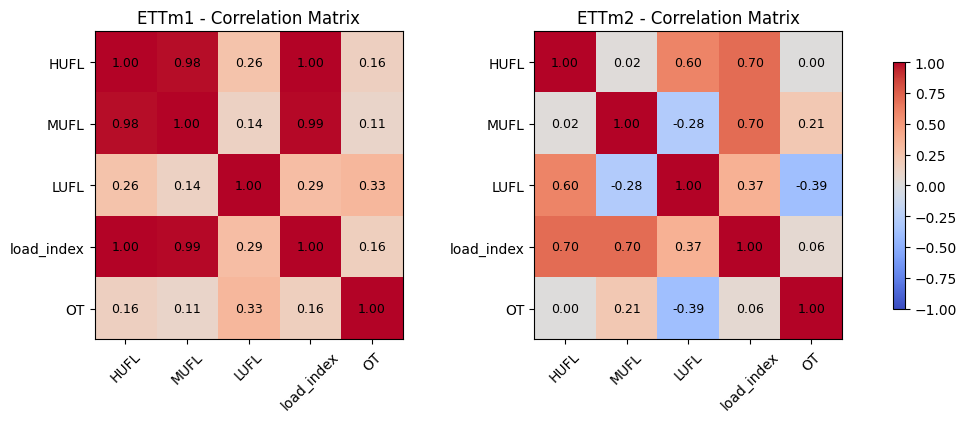

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, (name, df) in zip(
    axes, calibration_data.items()
):
    cols = ["HUFL", "MUFL", "LUFL", "load_index", "OT"]

    corr = df[cols].corr()

    im = ax.imshow(
        corr,
        cmap="coolwarm",
        vmin=-1,
        vmax=1
    )

    ax.set_xticks(range(len(cols)))
    ax.set_yticks(range(len(cols)))
    ax.set_xticklabels(cols, rotation=45)
    ax.set_yticklabels(cols)

    for i in range(len(cols)):
        for j in range(len(cols)):
            ax.text(
                j, i,
                f"{corr.iloc[i, j]:.2f}",
                ha="center",
                va="center",
                fontsize=9
            )

    ax.set_title(f"{name} - Correlation Matrix")

fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

> **Nhận xét – tương quan đồng thời:** `load_index`–OT có Pearson r ≈ 0,16 (ETTm1) và ≈ 0,06 (ETTm2), đều yếu. Quan hệ giữa các biến tải có thể khác nhau giữa hai trạm; tương quan không hàm ý nhân quả.

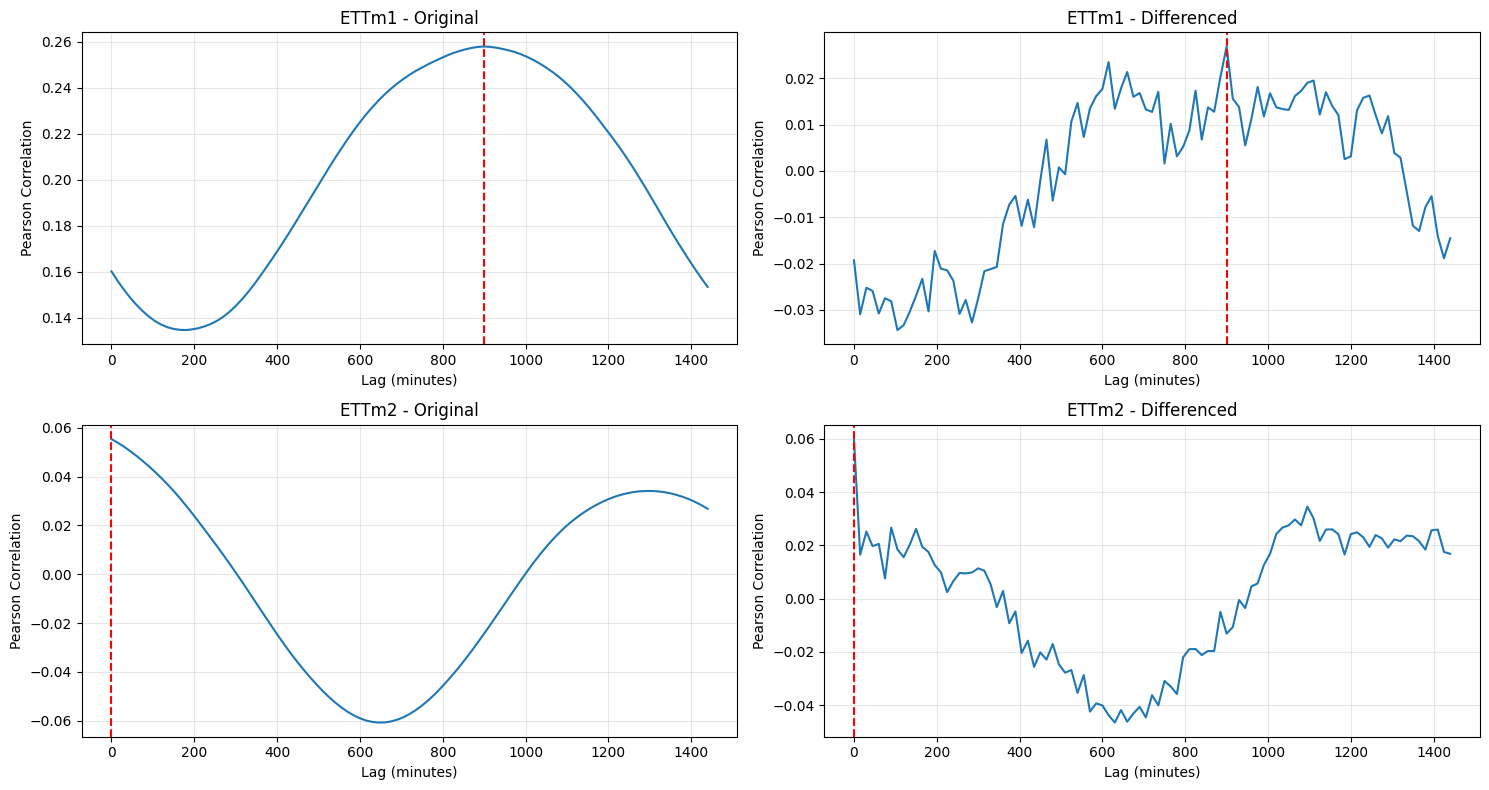

,Dataset,Method,Best Lag (steps),Best Lag (minutes),Max Correlation
0,ETTm1,Original,60,900,0.2578
1,ETTm1,Differenced,60,900,0.0268
2,ETTm2,Original,0,0,0.0554
3,ETTm2,Differenced,0,0,0.0599


In [ ]:
MAX_LAG = 96  # 96 * 15 minutes = 24 hours

fig, axes = plt.subplots(2, 2, figsize=(15, 8))
lag_results = []

for row, (name, df) in enumerate(calibration_data.items()):

    data = df.sort_values("date").copy()

    for col, ax in [
        ("Original", axes[row, 0]),
        ("Differenced", axes[row, 1])
    ]:
        load = data["load_index"]
        ot = data["OT"]

        if col == "Differenced":
            load = load.diff()
            ot = ot.diff()

        correlations = []

        for lag in range(MAX_LAG + 1):
            # Positive lag: earlier load vs later OT
            corr = load.shift(lag).corr(ot)
            correlations.append(corr)

        correlations = np.array(correlations)

        if np.all(np.isnan(correlations)):
            continue

        best_lag = int(np.nanargmax(correlations))
        best_corr = correlations[best_lag]

        lag_results.append({
            "Dataset": name,
            "Method": col,
            "Best Lag (steps)": best_lag,
            "Best Lag (minutes)": best_lag * 15,
            "Max Correlation": best_corr
        })

        ax.plot(
            np.arange(MAX_LAG + 1) * 15,
            correlations
        )

        ax.axvline(
            best_lag * 15,
            linestyle="--",
            color="red"
        )

        ax.set_title(f"{name} - {col}")
        ax.set_xlabel("Lag (minutes)")
        ax.set_ylabel("Pearson Correlation")
        ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

lag_summary = pd.DataFrame(lag_results)
display(lag_summary.round(4))

> **Nhận xét – cross-correlation:** ETTm1 đạt cực đại tại 900 phút: r = 0,2578 trên chuỗi gốc, nhưng chỉ r = 0,0268 trên chuỗi sai phân. ETTm2 đạt cực đại tại lag 0 với r ≈ 0,055–0,060. Đỉnh 15 giờ của ETTm1 có thể bị ảnh hưởng bởi chu kỳ/xu hướng; **chưa đủ căn cứ xem là độ trễ nhiệt thực**.

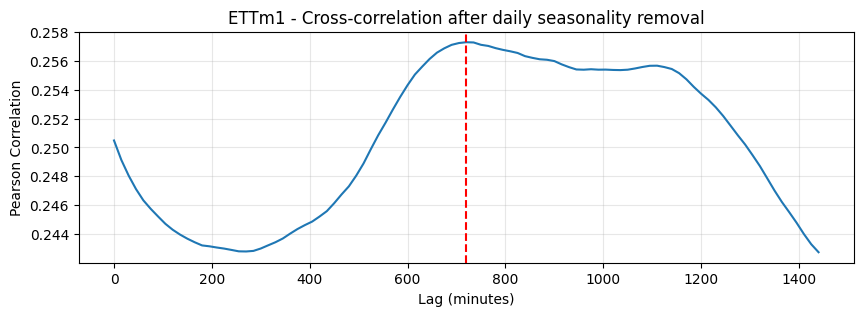

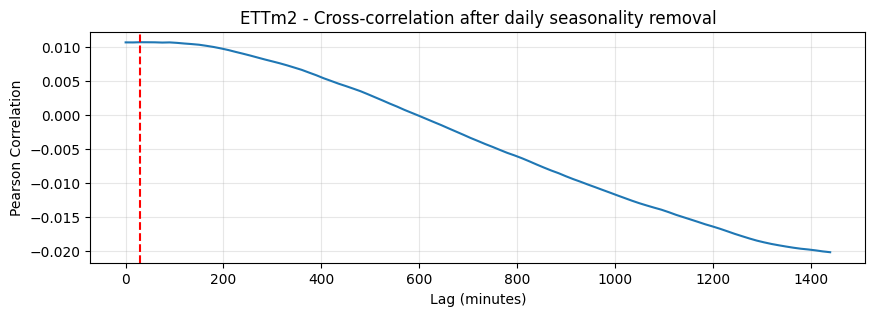

,Dataset,Best Lag,Lag (minutes),Correlation,Corr at lag 0
0,ETTm1,48,720,0.2573,0.2505
1,ETTm2,2,30,0.0107,0.0107


In [ ]:
MAX_LAG = 96
results = []

for name, df in calibration_data.items():
    data = df.sort_values("date").copy()

    # Mỗi ngày có 96 khung 15 phút
    data["slot"] = (
        data["date"].dt.hour * 4
        + data["date"].dt.minute // 15
    )

    # Loại bỏ chu kỳ ngày trung bình
    for col in ["load_index", "OT"]:
        daily_profile = data.groupby("slot")[col].transform("mean")
        data[f"{col}_residual"] = data[col] - daily_profile

    load = data["load_index_residual"]
    ot = data["OT_residual"]

    correlations = [
        load.shift(lag).corr(ot)
        for lag in range(MAX_LAG + 1)
    ]

    best_lag = int(np.nanargmax(correlations))

    results.append({
        "Dataset": name,
        "Best Lag": best_lag,
        "Lag (minutes)": best_lag * 15,
        "Correlation": correlations[best_lag],
        "Corr at lag 0": correlations[0]
    })

    plt.figure(figsize=(10, 3))
    plt.plot(np.arange(MAX_LAG + 1) * 15, correlations)
    plt.axvline(best_lag * 15, color="red", linestyle="--")
    plt.title(f"{name} - Cross-correlation after daily seasonality removal")
    plt.xlabel("Lag (minutes)")
    plt.ylabel("Pearson Correlation")
    plt.grid(alpha=0.3)
    plt.show()

display(pd.DataFrame(results).round(4))

> **Nhận xét – sau khi trừ mẫu giờ trong ngày:** ETTm1 đạt cực đại tại **720 phút (12 giờ), r = 0,2573**, khá gần r tại lag 0 (= 0,2505); đỉnh rộng nên chưa có lag duy nhất đáng tin cậy. ETTm2 đạt cực đại **30 phút, r = 0,0107**, gần bằng 0 → hầu như không thấy liên hệ tuyến tính theo độ trễ. Phép trừ mẫu giờ chưa loại hết xu hướng/mùa vụ. **Kết luận: chưa xác nhận được độ trễ k ổn định giữa `load_index` và OT.**